<a href="https://colab.research.google.com/github/namgiju/mlprog/blob/main/9%EC%A3%BC%EC%B0%A8/samsung_lstm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LSTM으로 삼성전자 주가 예측하기

사진 4장의 코드를 순서대로 옮긴 실습 노트북입니다.

- 윈도 크기 30, 테스트 데이터 마지막 200개, 학습 100 epochs입니다.
- 학습 결과와 실제값·예측값 비교 그래프를 포함합니다.
- 그래프는 원화 가격이 아닌 정규화된 시가를 비교합니다.
- 교재의 전체 데이터 정규화 방식을 사용했습니다. 엄밀한 성능 평가에서는 학습 데이터에만 scaler를 fit해야 합니다.

## 1. 필요한 라이브러리 설치 및 불러오기

In [ ]:
%pip install -q finance-datareader


In [ ]:
import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


## 2. 삼성전자 데이터 불러오기

In [ ]:
samsung = fdr.DataReader('005930', '2016')
print(samsung)


              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  194400  187000  194200   8670704  0.003618

[2660 rows x 6 columns]


In [ ]:
openValues = samsung[['Open']]


## 3. 특징값 정규화

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(openValues)


## 4. 훈련 데이터와 테스트 데이터 분리

In [ ]:
TEST_SIZE = 200
train_data = scaled[:-TEST_SIZE]
test_data = scaled[-TEST_SIZE:]


## 5. 순차 훈련 데이터 생성

이전 30개 거래일의 시가로 다음 거래일의 시가를 예측합니다. 사진의 설명에는 60개라고 쓰여 있지만 실제 코드의 30을 따릅니다.

In [ ]:
def make_sample(data, window):
    train = []
    target = []
    for i in range(len(data) - window):
        train.append(data[i:i + window])
        target.append(data[i + window])
    return np.array(train), np.array(target)

X_train, y_train = make_sample(train_data, 30)


## 6. LSTM 모델 구축

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM

model = Sequential()
model.add(LSTM(16,
               input_shape=(X_train.shape[1], 1),
               activation='tanh',
               return_sequences=False))
model.add(Dense(1))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## 7. 모델 학습

100 epochs를 실행하므로 시간이 걸릴 수 있습니다.

In [ ]:
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, epochs=100, batch_size=16)


Epoch 1/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0025
Epoch 2/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 1.4081e-04
Epoch 3/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.6299e-05
Epoch 4/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.3465e-05
Epoch 5/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.3840e-05
Epoch 6/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.0487e-05
Epoch 7/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.7773e-05
Epoch 8/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.0069e-05
Epoch 9/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6.7161e-05
Epoch 10/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.3371e-05
Epoch 11/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 6.2700e-05
Epoch 12/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 5.7808e-05
Epoch 13/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.5896e-05
Epoch 14/100
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.

## 8. 테스트 데이터 예측

In [ ]:
X_test, y_test = make_sample(test_data, 30)
pred = model.predict(X_test)


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


## 9. 실제값과 예측값 비교 그래프

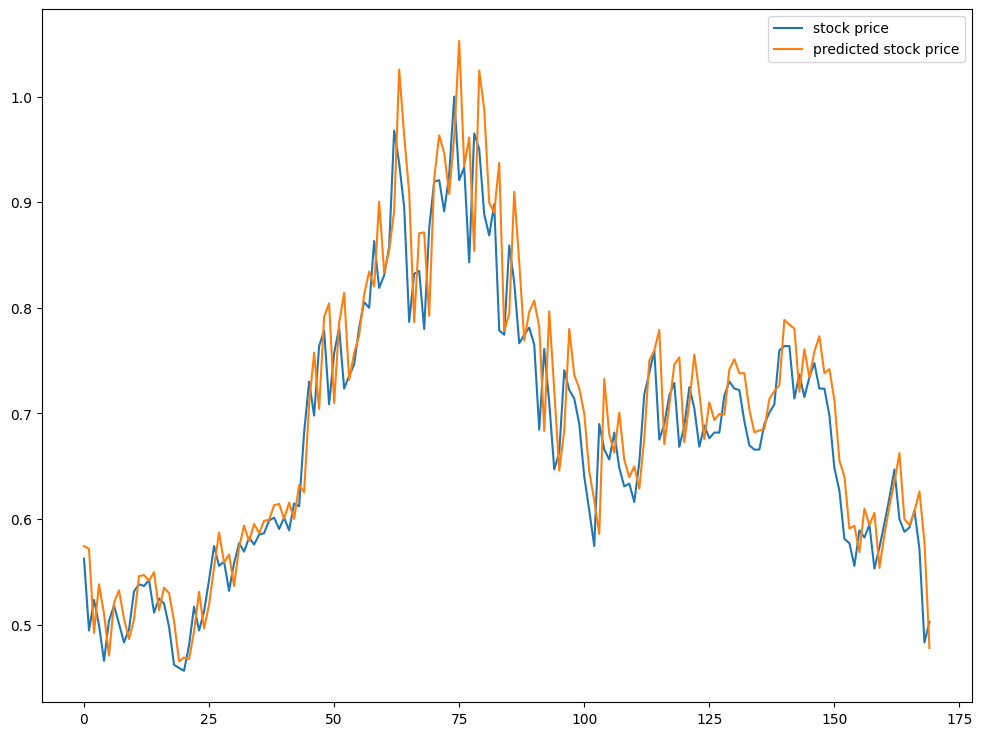

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 9))
plt.plot(y_test, label='stock price')
plt.plot(pred, label='predicted stock price')
plt.legend()
plt.show()
